# Libraries

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Model Parameters (from slide specifications)

In [2]:

params = {
    'c_s': 420.0,  # Soil water holding capacity (mm)
    'alpha': 4.0,  # Runoff function shape parameter (alpha >= 0)
    'gamma': 0.5,  # ET function shape parameter (gamma > 0)
    'beta_0': 0.8,  # Maximum ET fraction parameter (beta_0 <= 1)
}

# State Variable: Initial soil moisture (0.9 * c_s)

In [3]:
initial_soil_moisture = 0.9 * params['c_s']  # 378.0 mm

# Driving Data (Rainfall P and Radiation R for n number of days)

In [4]:
days = 1000
np.random.seed(42)
driving_data = pd.DataFrame({
    'day': np.arange(days),
    'rainfall': np.random.gamma(
        shape=2, scale=5, size=days
    ),  # Daily precipitation P_n (mm)
    'radiation': 4.0
    + 1.5 * np.sin(np.arange(days) / days * 2 * np.pi),  # Daily net radiation R_n (mm eq)
})

# Model Components output

In [5]:
print("Model Components:")
print("\nParameters:")
for param, value in params.items():
  print(f"  {param}: {value}")
print(f"\nInitial Soil Moisture: {initial_soil_moisture:.1f} mm")
print("\nDriving Data Summary:")
print(f"  Total Rainfall (P): {driving_data['rainfall'].sum():.1f} mm")
print(
    f"  Average Radiation (R): {driving_data['radiation'].mean():.2f} mm/day"
)

Model Components:

Parameters:
  c_s: 420.0
  alpha: 4.0
  gamma: 0.5
  beta_0: 0.8

Initial Soil Moisture: 378.0 mm

Driving Data Summary:
  Total Rainfall (P): 10299.7 mm
  Average Radiation (R): 4.00 mm/day


# Core Flux & State Functions


In [6]:
def calculate_runoff(soil_moisture, precipitation, c_s, alpha):
  """Calculates runoff Q_n = P_n * (SM_n / c_s)^alpha"""
  runoff_fraction = (soil_moisture / c_s) ** alpha
  return precipitation * runoff_fraction

def calculate_evapotranspiration(soil_moisture, radiation, c_s, gamma, beta_0):
  """Calculates evapotranspiration ET_n = R_n * beta_0 * (SM_n / c_s)^gamma"""
  et_fraction = beta_0 * ((soil_moisture / c_s) ** gamma)
  return radiation * et_fraction

def update_soil_moisture(
    current_sm, precipitation, radiation, params, delta_t=1.0
):
  """Updates soil moisture state using the forward water balance equation:

  SM_{n+1} = SM_n + (P_n - Q_n - ET_n) * delta_t
  """
  Q = calculate_runoff(
      current_sm, precipitation, params['c_s'], params['alpha']
  )
  ET = calculate_evapotranspiration(
      current_sm,
      radiation,
      params['c_s'],
      params['gamma'],
      params['beta_0'],
  )
   # Update equation
  next_sm = current_sm + (precipitation - Q - ET) * delta_t
  
  # Ensure physically realistic bounds [0, c_s]
  next_sm = max(0.0, min(params['c_s'], next_sm))
  
  return next_sm, Q, ET

# Simulation Loop

In [7]:
sm_history = []
q_history = []
et_history = []

current_sm = initial_soil_moisture

# TABLE HEADER 
print(
    f"{'Day':>3} | {'P (mm)':>7} | {'R (mm)':>7} | {'Q (mm)':>7} | {'ET (mm)':>7}"
    f' | {"SM (mm)":>9}'
)
print('-' * 55)

# Run the loop
for day, row in driving_data.iterrows():
  rain = row['rainfall']
  rad = row['radiation']

  # Calculate soil moisture and fluxes
  current_sm, Q, ET = update_soil_moisture(current_sm, rain, rad, params)

  # Save variables
  sm_history.append(current_sm)
  q_history.append(Q)
  et_history.append(ET)

  # Print the simulated values as a table les are updated)
  if day % 10 == 0 or day < 3:
    print(
        f'{day + 1:3d} | {rain:7.1f} | {rad:7.1f} | {Q:7.2f} | {ET:7.2f} |'
        f' {current_sm:9.1f}'
    )

driving_data['soil_moisture'] = sm_history
driving_data['runoff'] = q_history
driving_data['ET'] = et_history

Day |  P (mm) |  R (mm) |  Q (mm) | ET (mm) |   SM (mm)
-------------------------------------------------------
  1 |    12.0 |     4.0 |    7.85 |    3.04 |     379.1
  2 |     7.5 |     4.0 |    4.96 |    3.05 |     378.5
  3 |     6.9 |     4.0 |    4.56 |    3.05 |     377.8
 11 |     3.4 |     4.1 |    2.25 |    3.12 |     378.2
 21 |    14.9 |     4.2 |    9.49 |    3.17 |     377.7
 31 |    10.6 |     4.3 |    6.86 |    3.24 |     377.1
 41 |    14.8 |     4.4 |    9.44 |    3.31 |     377.6
 51 |     4.1 |     4.5 |    2.78 |    3.40 |     378.4
 61 |     2.1 |     4.6 |    1.39 |    3.45 |     375.1
 71 |     7.2 |     4.6 |    4.86 |    3.54 |     380.0
 81 |     3.7 |     4.7 |    2.36 |    3.57 |     373.1
 91 |    12.2 |     4.8 |    7.61 |    3.62 |     374.4
101 |    16.2 |     4.9 |   10.58 |    3.70 |     379.4
111 |     3.2 |     5.0 |    2.05 |    3.76 |     374.3
121 |     3.8 |     5.0 |    2.23 |    3.76 |     364.6
131 |    13.3 |     5.1 |    8.44 |    3.85 |   

# Visualization

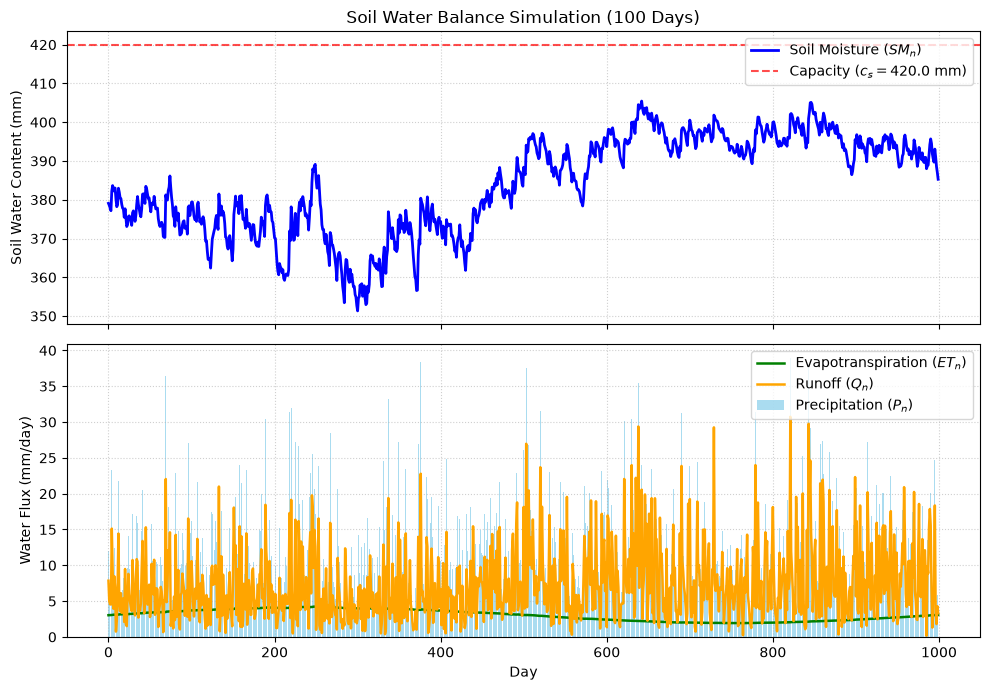

In [8]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 7), sharex=True)

# Soil Moisture State
ax1.plot(
    driving_data['day'],
    driving_data['soil_moisture'],
    color='blue',
    linewidth=2,
    label='Soil Moisture ($SM_n$)',
)
ax1.axhline(
    y=params['c_s'],
    color='red',
    linestyle='--',
    alpha=0.7,
    label=f"Capacity ($c_s = {params['c_s']}$ mm)",
)
ax1.set_ylabel('Soil Water Content (mm)')
ax1.set_title('Soil Water Balance Simulation (100 Days)')
ax1.legend(loc='upper right')
ax1.grid(True, linestyle=':', alpha=0.6)

# Daily Water Fluxes (P, Q, ET)
ax2.bar(
    driving_data['day'],
    driving_data['rainfall'],
    color='skyblue',
    alpha=0.7,
    label='Precipitation ($P_n$)',
)
ax2.plot(
    driving_data['day'],
    driving_data['ET'],
    color='green',
    linewidth=1.8,
    label='Evapotranspiration ($ET_n$)',
)
ax2.plot(
    driving_data['day'],
    driving_data['runoff'],
    color='orange',
    linewidth=1.8,
    label='Runoff ($Q_n$)',
)
ax2.set_xlabel('Day')
ax2.set_ylabel('Water Flux (mm/day)')
ax2.legend(loc='upper right')
ax2.grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
plt.show()